# Dice

Per pair and tool: move the 64mT label map onto the 3T grid with the pair's `.lta`, merge
left/right labels into regions, and compute Dice per region. The same transform is used for
both tools, so registration error is identical for the two.

In [16]:
import os

import nibabel as nib
import numpy as np
import pandas as pd

from common import OLD_OUT, LOGS, fs

REG, DICE = OLD_OUT / 'reg', OLD_OUT / 'dice'
TOOLS = ['SynthSeg', 'WMH_SynthSeg']

## Regions

17 regions, left/right merged; WMH also counted as WM. A region absent from both maps is not
reported.

In [17]:
# region -> (representative id, source labels)
# 5/44 (inf. lateral ventricle) merged into lateral ventricle: SynthSeg has it, WMH-SynthSeg does not.
REGIONS = {
    "WM":                (2,  [2, 41]),
    "Cortex":            (3,  [3, 42]),
    "Lateral-Ventricle": (4,  [4, 43, 5, 44]),
    "Cerebellum-WM":     (7,  [7, 46]),
    "Cerebellum-Cortex": (8,  [8, 47]),
    "Thalamus":          (10, [10, 49]),
    "Caudate":           (11, [11, 50]),
    "Putamen":           (12, [12, 51]),
    "Pallidum":          (13, [13, 52]),
    "3rd-Ventricle":     (14, [14]),
    "4th-Ventricle":     (15, [15]),
    "Brainstem":         (16, [16]),
    "Hippocampus":       (17, [17, 53]),
    "Amygdala":          (18, [18, 54]),
    "CSF":               (24, [24]),
    "Accumbens":         (26, [26, 58]),
    "VentralDC":         (28, [28, 60]),
    "WMH":               (77, [77]),          # WMH-SynthSeg only; also counted as WM
}
META = ['pair_id', 'subject', 'session', 'run', 'modality']


def harmonize(src, dst):
    """Save the merged label map (without 77) to dst; return {region: boolean mask}."""
    img = nib.load(src)
    v = np.rint(np.asarray(img.dataobj)).astype(np.int32)   # WMH-SynthSeg output is float32
    masks = {name: np.isin(v, labels) for name, (_, labels) in REGIONS.items()}
    masks["WM"] |= v == 77
    out = np.zeros_like(v)
    for name, (rid, _) in REGIONS.items():
        if name != "WMH":
            out[masks[name]] = rid
    o = nib.Nifti1Image(out, img.affine)     # affine only: avoid inheriting scl_slope from float32 headers
    o.set_data_dtype(np.int32)
    nib.save(o, dst)
    return masks


def dice(A, B):
    na, nb, i = int(A.sum()), int(B.sum()), int((A & B).sum())
    return dict(dice_np=2 * i / (na + nb), jaccard=i / (na + nb - i),
                voldiff=(nb - na) / ((na + nb) / 2), n_3T=na, n_64mT=nb)

## Compute and save

One Dice table per tool and 3T resolution. The moved and merged label maps are kept in
`dice/work/`. An existing table is skipped.

In [18]:
def dice_table(pairs, tool, acq, xfm, work, out_csv, log):
    if out_csv.exists():
        return
    work.mkdir(parents=True, exist_ok=True)
    out = []
    for r in pairs.to_dict('records'):
        pid = r['pair_id']
        print(pid)
        moved = work / f'{pid}_64mT_native.nii.gz'
        fs(f"mri_vol2vol --mov {r['mov_' + tool]} --targ {r['fix_' + tool]} --lta {xfm}/{pid}.lta "
           f"--nearest --o {moved} --no-save-reg", log=log, show=False)
        A = harmonize(r['fix_' + tool], work / f'{pid}_3T_h.nii.gz')    # 3T reference
        B = harmonize(moved, work / f'{pid}_64mT_h.nii.gz')             # registered 64mT
        for name in REGIONS:
            if A[name].any() or B[name].any():                          # empty in both -> not reported
                out.append({k: r[k] for k in META} | dict(tool=tool, acq=acq, region=name)
                           | dice(A[name], B[name]))
    pd.DataFrame(out).to_csv(out_csv, index=False)
    print(f'{len(out)} rows -> {out_csv}')


for acq in ['lowres', 'highres']:
    pairs = pd.read_csv(REG / f'pairs_{acq}.csv', keep_default_na=False)
    files = [f for t in TOOLS for f in pairs[f'mov_{t}']] + [f for t in TOOLS for f in pairs[f'fix_{t}']]
    missing = [f for f in files if not os.path.exists(f)]
    assert not missing, f'{len(missing)} label maps missing, e.g. {missing[:3]}'
    for tool in TOOLS:
        dice_table(pairs, tool, acq, REG / f'xfm_{acq}', DICE / 'work' / f'{tool}_{acq}',
                   DICE / f'dice_{tool}_{acq}.csv', LOGS / 'dice_old.log')

## Dice calculation result

Four Dice tables, one per tool and 3T reference (64mT vs 3T lowres, 64mT vs 3T highres),
saved as `dice/dice_<tool>_<acq>.csv`. Each has 61 pairs; one row per pair and region.
Below, repeated scans of a subject are averaged first, so every subject counts once (n = 11).

**Output of Dice calculation: 2 tools × 2 comparisons**

In [19]:
import matplotlib.pyplot as plt

ACQS = ['lowres', 'highres']
dice = pd.concat([pd.read_csv(DICE / f'dice_{t}_{a}.csv') for t in TOOLS for a in ACQS])

In [20]:
pd.DataFrame([
    dict(file=f'dice_{t}_{a}.csv', tool=t, comparison=f'64mT vs 3T {a}',
         pairs=d.pair_id.nunique(), regions=d.region.nunique())
    for (t, a), d in dice.groupby(['tool', 'acq'], sort=False)
]).set_index('file')

,tool,comparison,pairs,regions
file,,,,
dice_SynthSeg_lowres.csv,SynthSeg,64mT vs 3T lowres,61,17
dice_SynthSeg_highres.csv,SynthSeg,64mT vs 3T highres,61,17
dice_WMH_SynthSeg_lowres.csv,WMH_SynthSeg,64mT vs 3T lowres,61,18
dice_WMH_SynthSeg_highres.csv,WMH_SynthSeg,64mT vs 3T highres,61,18


In [21]:
# one value per subject: average repeated sessions / runs first
subj = dice.groupby(['tool', 'acq', 'subject', 'modality', 'region'], as_index=False).dice_np.mean()

In [22]:
def median_table(tool):
    t = subj[subj.tool == tool].pivot_table(index='region', columns='acq', values='dice_np', aggfunc='median')
    return t.loc[[r for r in REGIONS if r in t.index], ACQS].round(2)


def plot_dist(tool):
    """Box plot per region (one value per subject): line = median, box = Q1-Q3, dots = outliers."""
    d = subj[subj.tool == tool]
    regions = [r for r in REGIONS if r in set(d.region)]
    fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
    for ax, acq in zip(axes, ACQS):
        x = d[d.acq == acq]
        ax.boxplot([x[x.region == r].dice_np for r in regions], widths=0.6, patch_artist=True,
                   boxprops=dict(facecolor='lightgray'), medianprops=dict(color='k'),
                   flierprops=dict(markersize=3))
        ax.set(title=f'{tool}: 64mT vs 3T {acq}', ylabel='Dice', ylim=(0, 1))
        ax.grid(axis='y', alpha=0.3)
    axes[1].set_xticks(range(1, len(regions) + 1), regions, rotation=45, ha='right')
    plt.tight_layout()
    plt.show()

### WMH-SynthSeg

Dice values are tightly clustered in every region (small standard deviation), so mean and
median are almost the same. The median is reported.

In [23]:
median_table('WMH_SynthSeg')

acq,lowres,highres
region,,
WM,0.79,0.78
Cortex,0.71,0.71
Lateral-Ventricle,0.82,0.81
Cerebellum-WM,0.76,0.73
Cerebellum-Cortex,0.83,0.81
Thalamus,0.89,0.89
Caudate,0.84,0.85
Putamen,0.84,0.83
Pallidum,0.79,0.79


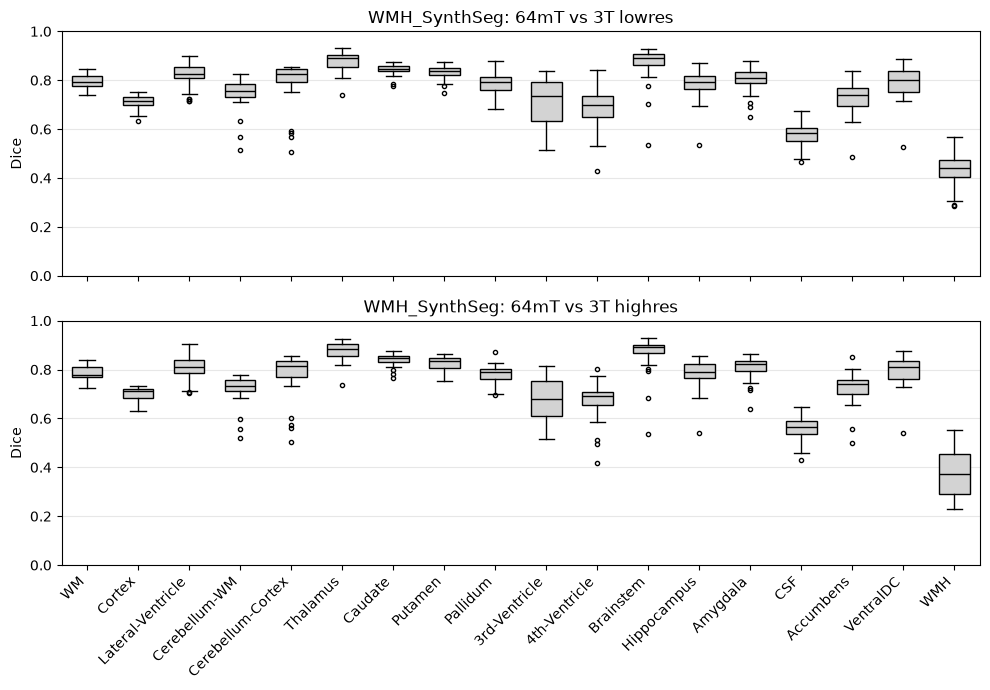

In [24]:
plot_dist('WMH_SynthSeg')

### SynthSeg

On a number of 64mT scans SynthSeg fails to segment a region, giving Dice close to 0 (e.g. the
4th ventricle is almost absent on many 64mT FLAIR and T1w scans). These failures pull the mean
down, so the median is reported.

In [25]:
median_table('SynthSeg')

acq,lowres,highres
region,,
WM,0.80,0.79
Cortex,0.73,0.72
Lateral-Ventricle,0.82,0.80
Cerebellum-WM,0.75,0.71
Cerebellum-Cortex,0.83,0.82
Thalamus,0.87,0.85
Caudate,0.82,0.81
Putamen,0.78,0.78
Pallidum,0.67,0.65


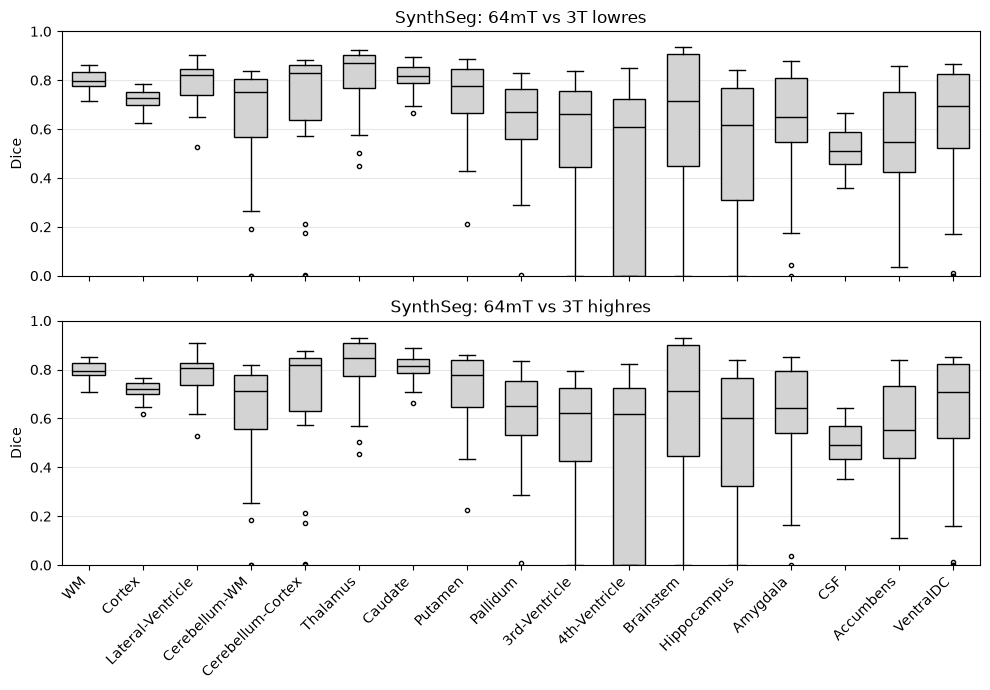

In [26]:
plot_dist('SynthSeg')

## WMH-SynthSeg vs SynthSeg

Each tool's 64mT segmentation is compared with its own 3T lowres segmentation (lowres limits the
effect of resolution). Bar = median of 11 subjects, error bar = Q1–Q3, k/11 = subjects where
WMH-SynthSeg is higher. Regions are ordered from large to small.

In [27]:
SIZE_ORDER = ['WM', 'Cortex', 'Cerebellum-Cortex', 'Cerebellum-WM', 'Brainstem', 'Lateral-Ventricle',
              'CSF', 'Thalamus', 'Putamen', 'Hippocampus', 'Caudate', 'VentralDC', 'Pallidum',
              'Amygdala', '3rd-Ventricle', '4th-Ventricle', 'Accumbens']      # large -> small
COLORS = {'SynthSeg': '#c4c4c4', 'WMH_SynthSeg': '#2a78d6'}


def plot_compare(acq='lowres'):
    """Per sequence: median Dice of 11 subjects, bars = Q1-Q3; k/n = subjects where WMH-SynthSeg is higher."""
    d = subj[(subj.acq == acq) & subj.region.isin(SIZE_ORDER)]
    x = np.arange(len(SIZE_ORDER))
    fig, axes = plt.subplots(3, 1, figsize=(12, 11), sharex=True)
    for ax, mod in zip(axes, ['T2w', 'T1w', 'FLAIR']):
        w = d[d.modality == mod].pivot_table(index='subject', columns=['tool', 'region'], values='dice_np')
        for i, tool in enumerate(TOOLS):
            q = w[tool][SIZE_ORDER].quantile([0.25, 0.5, 0.75])
            ax.bar(x + (i - 0.5) * 0.4, q.loc[0.5], 0.4, color=COLORS[tool], label=tool,
                   yerr=[q.loc[0.5] - q.loc[0.25], q.loc[0.75] - q.loc[0.5]],
                   error_kw=dict(lw=0.8, capsize=2, ecolor='0.3'))
        k = (w['WMH_SynthSeg'][SIZE_ORDER] > w['SynthSeg'][SIZE_ORDER]).sum()
        for xi, ki in zip(x, k):
            ax.text(xi, 1.02, f'{ki}/{len(w)}', ha='center', fontsize=8, color='0.4')
        ax.set(title=f'{mod}: 64mT vs 3T {acq}', ylabel='Dice', ylim=(0, 1.1), yticks=np.arange(0, 1.01, 0.2))
        ax.grid(axis='y', alpha=0.3)
        ax.set_axisbelow(True)
        ax.spines[['top', 'right']].set_visible(False)
    fig.legend(*axes[0].get_legend_handles_labels(), loc='upper right', ncol=2, frameon=False)
    axes[-1].set_xticks(x, SIZE_ORDER, rotation=45, ha='right')
    fig.suptitle(f'WMH-SynthSeg vs SynthSeg (3T {acq})', x=0.02, ha='left')
    plt.tight_layout()
    plt.show()

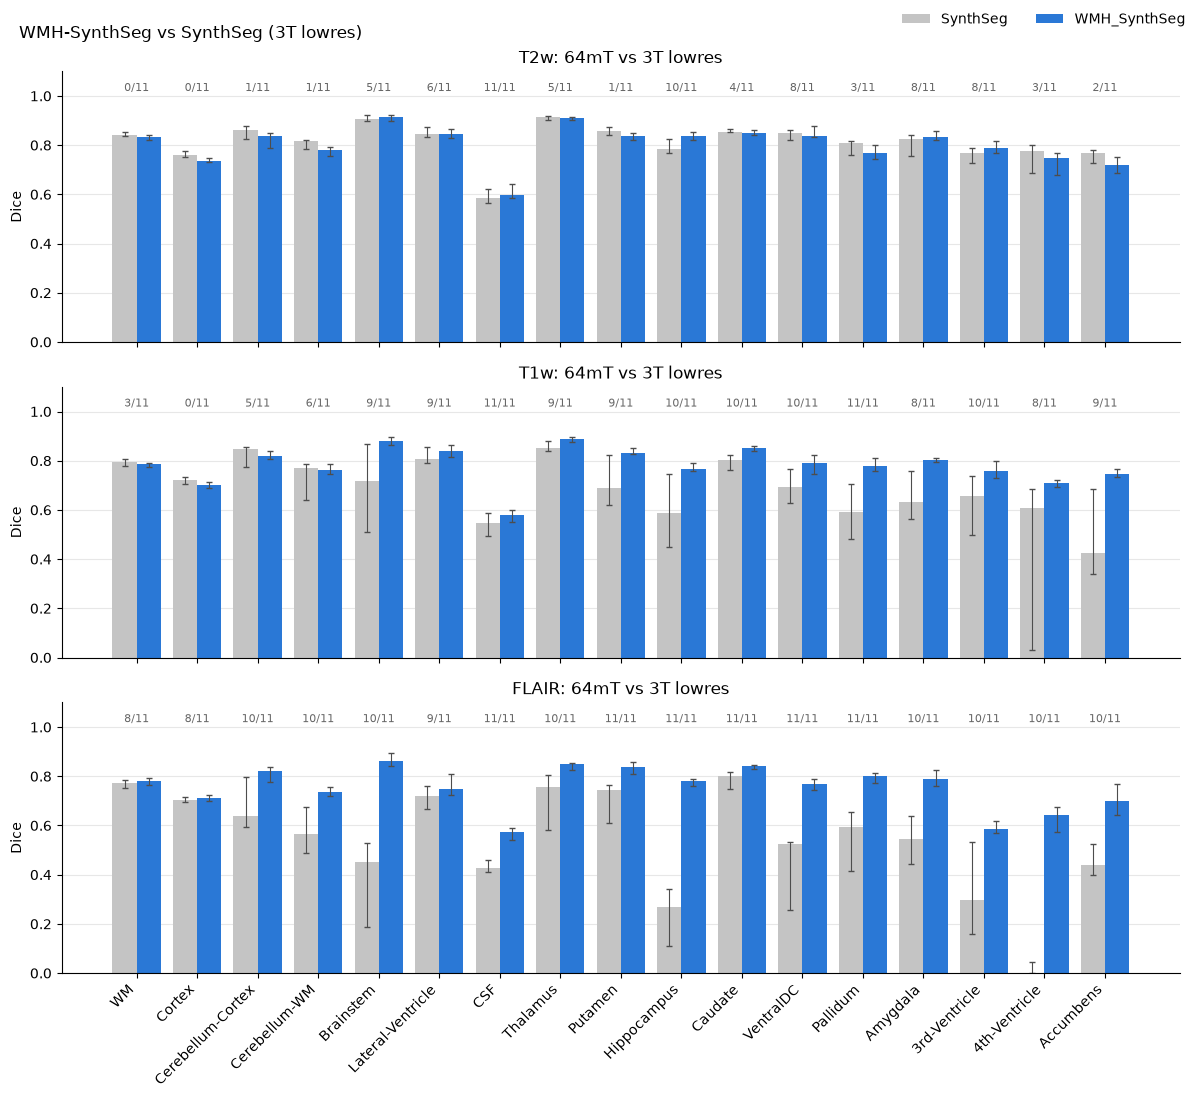

In [28]:
plot_compare()

## Where SynthSeg fails

A median hides the failures. In some pairs SynthSeg misses a structure almost entirely
(Dice < 0.1) while cortex and white matter score normally. Number of pairs per region
(64mT vs 3T lowres, 61 pairs):

In [35]:
lo = dice[dice.acq == 'lowres']
fail = (lo.assign(fail=lo.dice_np < 0.1)
          .pivot_table(index='region', columns='tool', values='fail', aggfunc='sum', fill_value=0)[TOOLS])
fail[fail.SynthSeg > 0].sort_values('SynthSeg', ascending=False)

tool,SynthSeg,WMH_SynthSeg
region,,
4th-Ventricle,28,0
3rd-Ventricle,8,0
VentralDC,5,0
Hippocampus,5,0
Brainstem,4,0
Amygdala,3,0
Cerebellum-WM,3,0
Cerebellum-Cortex,3,0
Pallidum,3,0


WMH-SynthSeg never falls below 0.1. Three of these pairs as axial slices. A row is one tool;
the columns are the 64mT segmentation, the 64mT image, the 3T image and the 3T segmentation.
Each scan stays in its own space (3T and 64mT are separate scanner frames, so the two slices can
cut the head at slightly different angles); the slice goes through the centre of the named
structure.

In [36]:
import matplotlib.pyplot as plt
from nibabel.processing import resample_from_to

PAIRS = pd.read_csv(REG / 'pairs_lowres.csv', keep_default_na=False).set_index('pair_id')

# FreeSurfer LUT colours, left and right the same; white matter (2/41) left uncoloured
LUT = {3: (205, 62, 78), 4: (120, 18, 134), 5: (196, 58, 250), 7: (220, 248, 164),
       8: (230, 148, 34), 10: (0, 118, 14), 11: (122, 186, 220), 12: (236, 13, 176),
       13: (12, 48, 255), 14: (204, 182, 142), 15: (42, 204, 164), 16: (119, 159, 176),
       17: (220, 216, 20), 18: (103, 255, 255), 24: (60, 60, 60), 26: (255, 165, 0),
       28: (165, 42, 42), 77: (200, 70, 255)}
for l, r in [(3, 42), (4, 43), (5, 44), (7, 46), (8, 47), (10, 49), (11, 50), (12, 51),
             (13, 52), (17, 53), (18, 54), (26, 58), (28, 60)]:
    LUT[r] = LUT[l]
RGBA = np.zeros((max(LUT) + 1, 4))
for k, c in LUT.items():
    RGBA[k] = (*np.array(c) / 255, 0.55)


def show_failure(pair_id, regions):
    """Axial slice through the centre of regions[0], one row per tool. Columns: 64mT segmentation,
    64mT image, 3T image, 3T segmentation. Each scan stays in its own space; the centre is taken
    from WMH-SynthSeg's map, because SynthSeg's may not contain the structure."""
    r = PAIRS.loc[pair_id]
    fig, axes = plt.subplots(2, 4, figsize=(16, 8.5))
    for side, (c_img, c_seg) in [('mov', (1, 0)), ('fix', (2, 3))]:
        anchor = nib.as_closest_canonical(nib.load(r[f'{side}_WMH_SynthSeg']))
        mask = np.isin(np.rint(np.asarray(anchor.dataobj)), REGIONS[regions[0]][1])
        xyz = anchor.affine @ [*np.argwhere(mask).mean(0), 1]           # centre in scanner coordinates
        for row, tool in enumerate(TOOLS):
            seg = nib.load(r[f'{side}_{tool}'])
            img = nib.as_closest_canonical(resample_from_to(nib.load(r[f'{side}_raw']), seg, order=1))
            seg = nib.as_closest_canonical(seg)
            k = int(round((np.linalg.inv(seg.affine) @ xyz)[2]))       # axial slice index
            lab = np.rint(np.asarray(seg.dataobj)[:, :, k]).astype(int).T
            lab[lab >= len(RGBA)] = 0
            im = np.asarray(img.dataobj)[:, :, k].T
            ys, xs = np.nonzero(lab)
            box = np.s_[max(ys.min() - 5, 0):ys.max() + 6, max(xs.min() - 5, 0):xs.max() + 6]
            lo, hi = np.percentile(im[box], [0.5, 99.5])
            for c in (c_img, c_seg):
                ax = axes[row, c]
                ax.imshow(im[box], cmap='gray', vmin=lo, vmax=hi, origin='lower')
                if c == c_seg:
                    ax.imshow(RGBA[lab][box], origin='lower')
                ax.axis('off')
    for c, t in enumerate(['segmentation @ 64mT', '64mT image', '3T image', 'segmentation @ 3T']):
        axes[0, c].set_title(t)
    for row, tool in enumerate(TOOLS):
        axes[row, 0].text(-0.04, 0.5, tool.replace('_', '-'), rotation=90, ha='right', va='center',
                          fontsize=12, transform=axes[row, 0].transAxes)
    d = dice[(dice.acq == 'lowres') & (dice.pair_id == pair_id)].pivot(index='region', columns='tool',
                                                                         values='dice_np')
    note = '     |     '.join(f'{g}: SynthSeg {d.loc[g, "SynthSeg"]:.2f} -> WMH-SynthSeg '
                              f'{d.loc[g, "WMH_SynthSeg"]:.2f}' for g in regions)
    fig.suptitle(f"{r['subject']}  |  {r['modality']}  |  3T lowres  vs  64mT {r['session']}", fontsize=14)
    fig.text(0.5, 0.01, f'axial slice through the {regions[0]} centre of each scan  |  FreeSurfer LUT\n'
                        f'Dice (64mT vs 3T lowres, within tool)   {note}', ha='center', fontsize=9, color='0.4')
    plt.tight_layout(rect=(0.02, 0.04, 1, 0.97))
    plt.show()

**sub-0015, FLAIR, 4th ventricle.** SynthSeg's 64mT map has no 4th ventricle (Dice 0.00;
WMH-SynthSeg 0.75), and the brainstem is only partly labelled (0.48 vs 0.91).

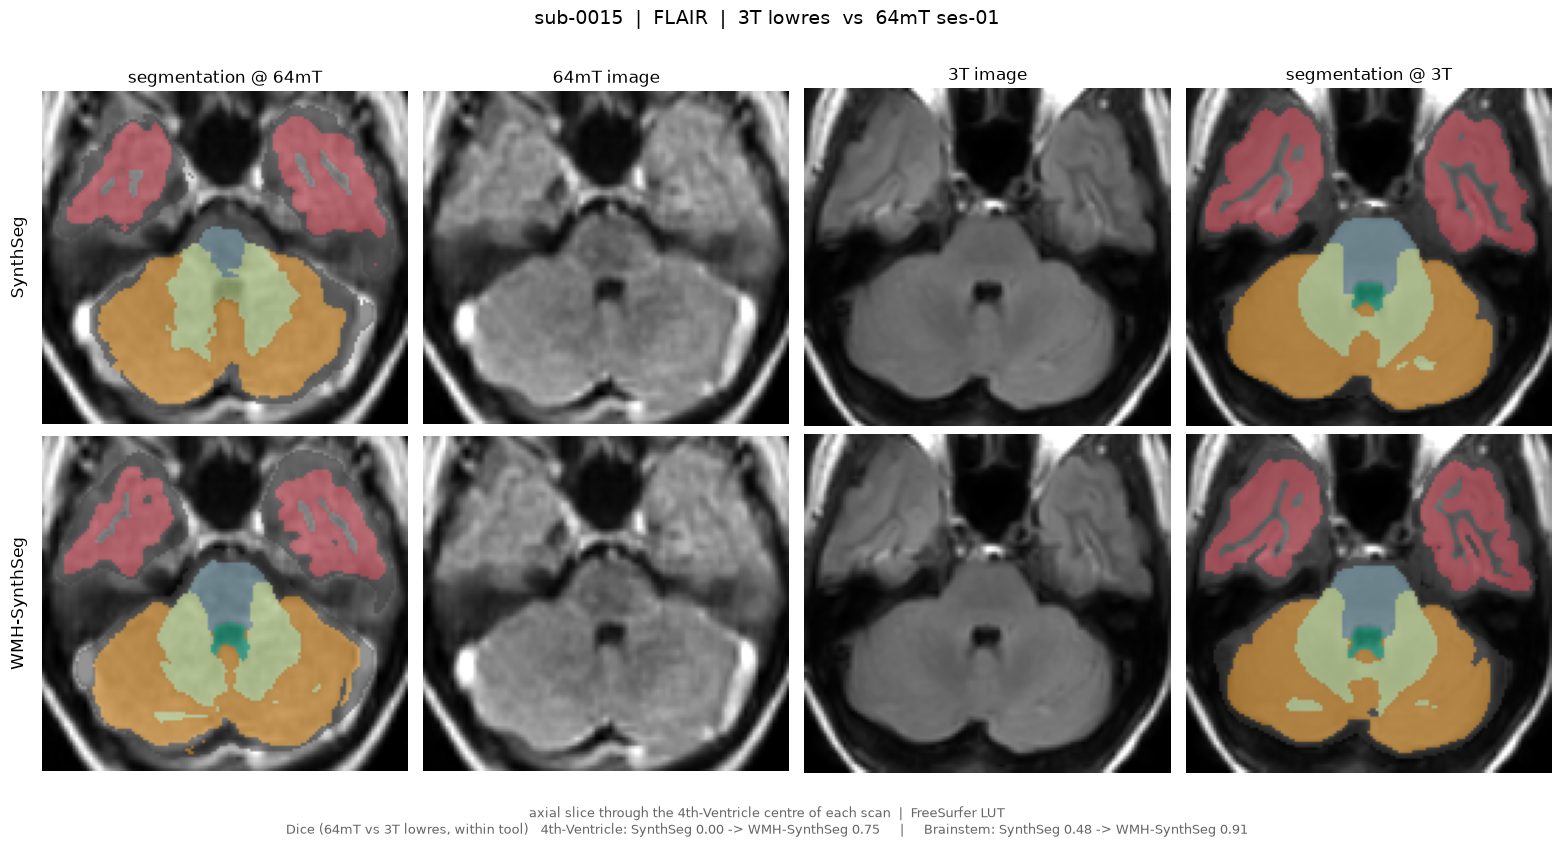

In [37]:
show_failure('sub-0015_ses-01_run-1_FLAIR__lowres', ['4th-Ventricle', 'Brainstem'])

**sub-0066, FLAIR, brainstem.** SynthSeg labels the brainstem as cerebellum and spreads cortex
over one side of the posterior fossa. Brainstem, hippocampus and ventral DC are all but missing
(Dice ≤ 0.01; WMH-SynthSeg 0.80–0.88).

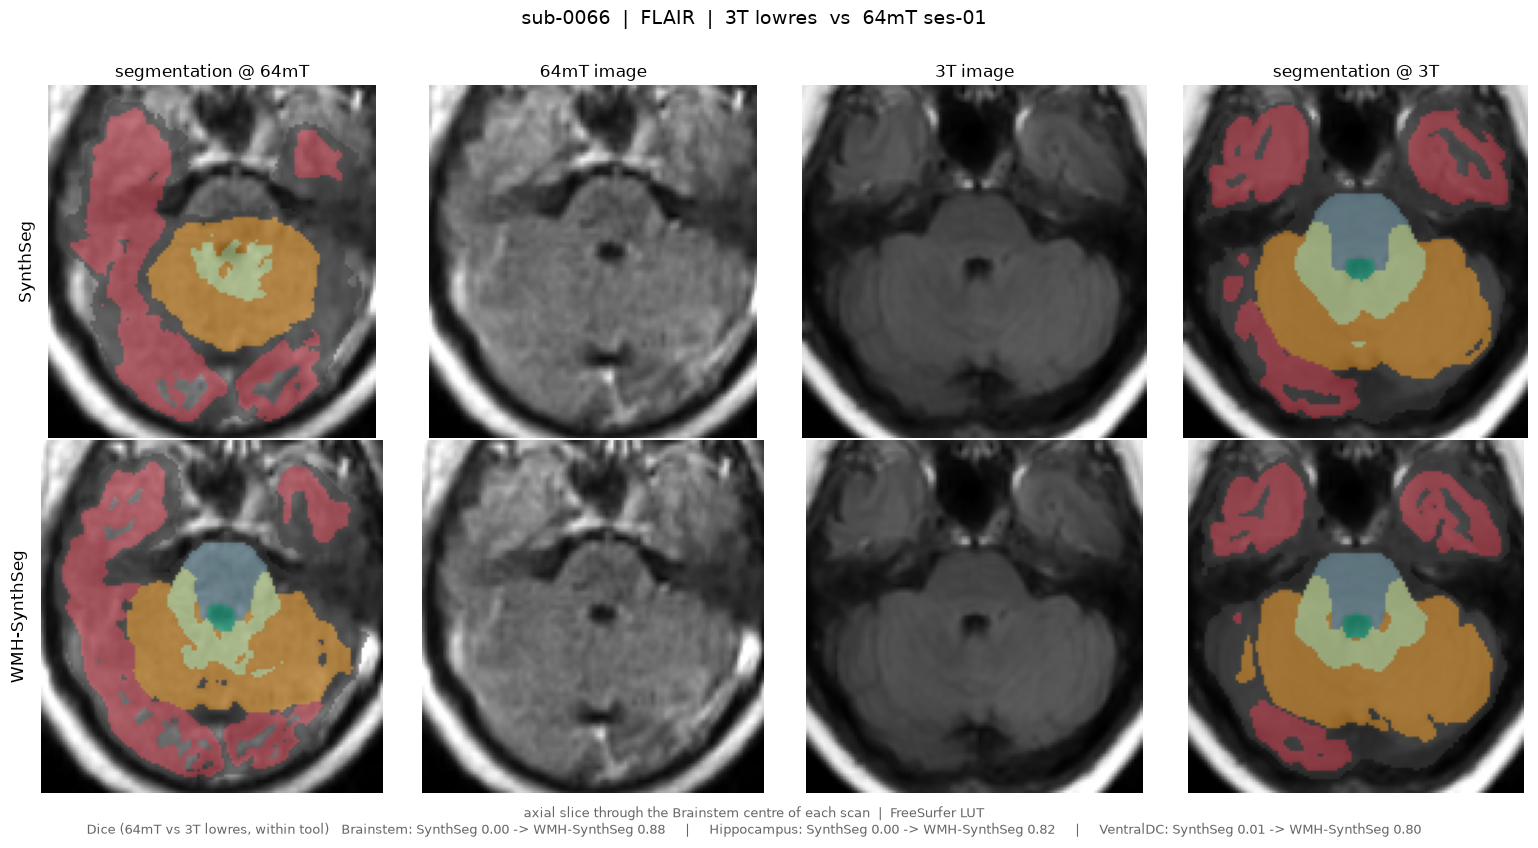

In [38]:
show_failure('sub-0066_ses-01_run-1_FLAIR__lowres', ['Brainstem', 'Hippocampus', 'VentralDC'])

**sub-0027 ses-01, T1w, deep grey matter.** SynthSeg loses the deep grey matter on this scan:
3rd ventricle, pallidum and thalamus at Dice 0.00, 0.00 and 0.18; WMH-SynthSeg 0.81, 0.75 and 0.88.

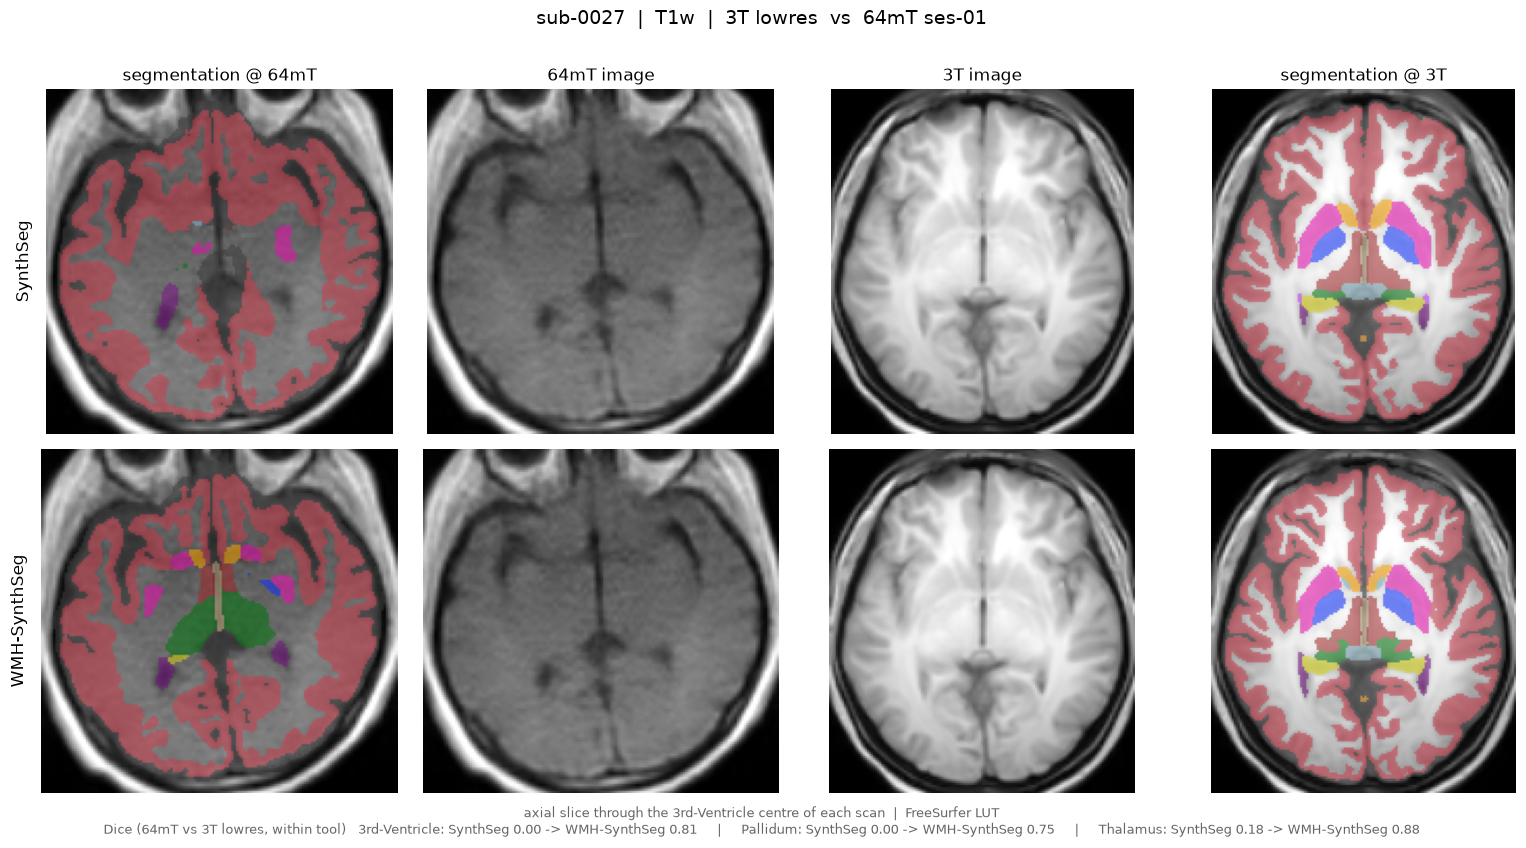

In [39]:
show_failure('sub-0027_ses-01_run-1_T1w__lowres', ['3rd-Ventricle', 'Pallidum', 'Thalamus'])

In each case WMH-SynthSeg, run on the same 64mT scan, finds the structure. SynthSeg's failures
are outright omissions, not poorly drawn boundaries.

## Scans cut off at the bottom

"Cut off" means that part of a structure lies outside the scanned volume: the image ends before
the structure does. In the old dataset the scanned volume is short from bottom to top: 200 mm on
64mT (40 slices × 5 mm) and about 155 mm on 3T lowres (31 slices × 5 mm). Where it was placed too
high, the lower cerebellum and brainstem were not scanned. The new dataset does not have this
problem (Chapter 08).

### Two cases

Coronal and sagittal slices through the centre of the cerebellum, 64mT T1w. Blue = cerebellum,
red = brainstem (WMH-SynthSeg labels); yellow = edge of the scanned volume.

- **sub-0025** (top): the cerebellum ends well above the lower edge; the neck is visible below it.
- **sub-0011** (bottom): the cerebellum and brainstem run into the lower edge and are cut flat.
  The top of the head lies about 8 cm below the upper edge: the volume was placed too high.

In [ ]:
from matplotlib.patches import Rectangle

LOWRES = pd.read_csv(REG / 'pairs_lowres.csv', keep_default_na=False).set_index('pair_id')


def show_cut(pair_ids):
    """Coronal and sagittal slice through the cerebellum centre, 64mT image on the label-map grid."""
    fig, axes = plt.subplots(len(pair_ids), 2, figsize=(11, 5 * len(pair_ids)), squeeze=False)
    for row, pid in zip(axes, pair_ids):
        r = LOWRES.loc[pid]
        seg = nib.as_closest_canonical(nib.load(r['mov_WMH_SynthSeg']))
        img = resample_from_to(nib.load(r['mov_raw']), seg, order=1).get_fdata()
        lab = np.rint(np.asarray(seg.dataobj)).astype(int)
        cb, bs = np.isin(lab, [7, 8, 46, 47]), lab == 16
        c = np.argwhere(cb).mean(0).astype(int)                              # centre of the cerebellum
        for ax, (view, cut) in zip(row, [('coronal', 1), ('sagittal', 0)]):
            sl = [slice(None)] * 3
            sl[cut] = c[cut]
            im = img[tuple(sl)].T
            h, w = im.shape
            over = np.zeros((h, w, 4))
            over[cb[tuple(sl)].T] = [0.1, 0.4, 1, 0.45]                     # cerebellum: blue
            over[bs[tuple(sl)].T] = [1, 0.1, 0.1, 0.45]                     # brainstem: red
            ax.imshow(im, cmap='gray', origin='lower', vmax=np.percentile(img, 99.5))
            ax.imshow(over, origin='lower')
            ax.add_patch(Rectangle((-0.5, -0.5), w, h, fill=False, edgecolor='yellow', lw=1.5))
            ax.set_xlim(-15, w + 15)
            ax.set_ylim(-15, h + 15)
            ax.set_facecolor('tab:blue')
            ax.set_xticks([])
            ax.set_yticks([])
            ax.set_title(f"{r['subject']} {r['session']} {r['modality']}, {view}", fontsize=10)
    plt.tight_layout()
    plt.show()


show_cut(['sub-0025_ses-01_run-1_T1w__lowres', 'sub-0011_ses-01_run-1_T1w__lowres'])

### How many scans

A scan counts as cut off when its label map still has cerebellum or brainstem labels in its
lowest 5 mm. Checked on the 64mT and the 3T lowres label map of every pair; saved as
`dice/cut_off.csv`.

In [ ]:
CUT = DICE / 'cut_off.csv'


def lowest_5mm(path):
    """Cerebellum and brainstem label voxels in the lowest 5 mm of a 1 mm label map."""
    v = np.rint(np.asarray(nib.as_closest_canonical(nib.load(path)).dataobj)).astype(int)
    head = np.nonzero((v > 0).any(axis=(0, 1)))[0]
    low = v[:, :, :5]
    return int(np.isin(low, [7, 8, 46, 47]).sum()), int(np.isin(low, [16]).sum()), int(v.shape[2] - 1 - head.max())


if not CUT.exists():
    rows = []
    for pid, r in LOWRES.iterrows():
        cb64, bs64, top64 = lowest_5mm(r['mov_WMH_SynthSeg'])
        cb3, bs3, _ = lowest_5mm(r['fix_WMH_SynthSeg'])
        rows.append(dict(pair_id=pid, subject=r['subject'], session=r['session'], run=r['run'],
                         modality=r['modality'], cerebellum_64mT=cb64, brainstem_64mT=bs64,
                         empty_top_64mT_mm=top64, cerebellum_3T=cb3, brainstem_3T=bs3))
    c = pd.DataFrame(rows)
    c['cut_64mT'] = (c.cerebellum_64mT + c.brainstem_64mT) > 0
    c['cut_3T'] = (c.cerebellum_3T + c.brainstem_3T) > 0
    c['group'] = [{(0, 0): 'neither', (0, 1): '3T only', (1, 0): '64mT only', (1, 1): 'both'}[k]
                  for k in zip(c.cut_64mT, c.cut_3T)]
    c.to_csv(CUT, index=False)
cut = pd.read_csv(CUT, keep_default_na=False)
GROUPS = ['neither', '3T only', '64mT only', 'both']
(cut.groupby('modality').agg(pairs=('pair_id', 'size'), cut_64mT=('cut_64mT', 'sum'), cut_3T=('cut_3T', 'sum'))
 .loc[['T2w', 'T1w', 'FLAIR']])

64mT scans cut off, most cerebellum outside first (label voxels of 1 mm³ in the lowest 5 mm):

In [ ]:
(cut[cut.cut_64mT].sort_values('cerebellum_64mT', ascending=False)
 [['subject', 'session', 'run', 'modality', 'cerebellum_64mT', 'brainstem_64mT', 'empty_top_64mT_mm']]
 .reset_index(drop=True))

### Effect on Dice

Dice is computed on the 3T lowres grid, so tissue outside the 3T volume is left out of both maps.
The pairs fall into four groups. WMH-SynthSeg, all sequences together, one value per pair:
median Dice (number of pairs). Thalamus lies high in the head and is never cut off: it shows
whether the groups differ for other reasons than the cut.

In [ ]:
SHOWN = ['Brainstem', 'Cerebellum-Cortex', 'Cerebellum-WM', '4th-Ventricle', 'Cortex', 'CSF', 'Thalamus']
d = (dice[(dice.tool == 'WMH_SynthSeg') & (dice.acq == 'lowres') & dice.region.isin(SHOWN)]
     .merge(cut[['pair_id', 'group']], on='pair_id'))
q = d.groupby(['region', 'group']).dice_np.agg(['median', 'size'])
(q.apply(lambda r: f"{r['median']:.2f} ({int(r['size'])})", axis=1)
 .unstack('group').reindex(index=SHOWN, columns=GROUPS).fillna('-'))

What the cut does to Dice:

- **Cut off only on 3T** (21 pairs): nothing is lost. The part below the 3T volume is left out of
  both maps, and both maps end at the same plane, so Dice is even slightly higher (brainstem 0.91,
  4th ventricle 0.73, against 0.89 and 0.69 when neither is cut).
- **Cut off on both** (19 pairs): when the 64mT volume ends higher than the 3T volume, the strip
  between them is 3T only. The lower regions lose a little: cerebellum cortex 0.84 → 0.80,
  brainstem 0.89 → 0.87. Thalamus is the same in both groups (0.88), so the drop comes from the
  cut, not from the subjects.
- **Cut off only on 64mT** (2 pairs, 2 subjects): lower in every region, thalamus included: too
  few pairs, and the low values point to these two scans rather than to the cut.
- **Not affected**: cortex and CSF, the benchmark structures of Chapter 07, and every region
  higher in the head.
- The brainstem and cerebellum values of the old dataset (Dice here, volume in Chapter 06) are
  incomplete for the cut-off scans: they describe only the part inside the scanned volume, and
  the lower medulla and lowest cerebellum are never compared. The new dataset, which is not cut
  off (Chapter 08), is the more reliable reference for these regions.

## Conclusion

Each tool is compared with its own 3T segmentation. On 64mT scans:

- **FLAIR**: WMH-SynthSeg is higher in all 17 regions (median gain 0.19).
- **T1w**: WMH-SynthSeg is higher in 14 of 17 regions (median gain 0.10).
- **T2w**: the two tools are equal (median difference −0.01); SynthSeg is slightly higher on WM and cortex.
- The gain is largest in deep and small structures (brainstem, hippocampus, ventricles), and
  WMH-SynthSeg has shorter error bars, i.e. less variation between subjects.
- **Outright failures**: SynthSeg misses a structure almost entirely (Dice < 0.1) in 64
  region–pair cases, most often the 4th ventricle (28 of 61 pairs); WMH-SynthSeg never does.

- **Scans cut off at the bottom** lower the Dice of cerebellum and brainstem slightly when the
  64mT scan is cut higher than the 3T scan; cortex and CSF are not affected.

**WMH-SynthSeg is the more robust tool on 64mT scans.**